# REFIT Washing-Machine Disaggregation — Walkthrough

This notebook runs the three analysis stages end-to-end and displays the resulting figures/tables inline. The heavy lifting lives in `../src/*.py` (reusable, testable scripts); this notebook is a thin, narrated wrapper around them. See `../DATA.md`, `../RESULTS.md`, `../Recommendation.md` for the full write-up.

**Before running**: follow the "Getting the data" section in `../README.md` to download and extract the REFIT raw/clean CSVs, and `pip install -r ../requirements.txt`.

In [1]:
import os, sys, json
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = os.path.abspath('..')
SRC = os.path.join(ROOT, 'src')
FIG = os.path.join(ROOT, 'figures')
PROC = os.path.join(ROOT, 'data', 'processed')
sys.path.insert(0, SRC)

pd.set_option('display.width', 140)

## Part 1 — Raw data inspection and cleaning (House 1)

Runs `inspect_house1.py` (prints the raw findings grounding the cleaning thresholds) then `clean_house1.py` (the actual sort/dedupe/null-impossible-values/resample/gap-fill pipeline), and displays the before/after plots. Full narrative and numbers: `../DATA.md`.

In [2]:
import inspect_house1
inspect_house1.main()

rows: 4140886
time range: 2014-06-27 21:57:50 to 2015-07-10 11:56:32
already time-sorted: True
rows where time goes backwards vs previous row: 0


duplicate timestamp rows: 0 = 0.0 %
unique duplicated timestamps: 0

interval stats (seconds):
count    4.140885e+06
mean     7.878297e+00
std      5.826959e+02
min      1.000000e+00
25%      7.000000e+00
50%      7.000000e+00
75%      7.000000e+00
max      7.472520e+05
Name: Time, dtype: float64
median interval: 7.0
% of intervals == 6,7,8s (nominal): 97.85509619320507
count of gaps > 60s: 3603
count of gaps > 600s (10min): 59
count of gaps > 3600s (1hr): 19
largest 10 gaps (s):


3598314    747252.0
3853977    649243.0
639044     390740.0
3167070    376523.0
3070834    198423.0
3659903    179988.0
1252859    135709.0
3154793    129823.0
2998341    108860.0
1894337     86935.0
Name: Time, dtype: float64

NaN counts per column:
Time                0
Unix                0
Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64

Aggregate stats:
count    3.951913e+06
mean     4.464609e+02
std      8.139717e+02
min      1.500000e+01
25%      1.850000e+02
50%      2.340000e+02
75%      3.630000e+02
max      2.915900e+04
Name: Aggregate, dtype: float64
Aggregate negative count: 0
Aggregate > 20000W count: 74
Aggregate > 15000W count: 104
Aggregate > 10000W count: 10941


Aggregate top 10 values: [29159.0, 28950.0, 28855.0, 24732.0, 24000.0, 24000.0, 24000.0, 24000.0, 24000.0, 24000.0]
Appliance1: max=76677.0, negative=0, >4000W=184
Appliance2: max=66685.0, negative=0, >4000W=22
Appliance3: max=73725.0, negative=0, >4000W=80
Appliance4: max=98301.0, negative=0, >4000W=71
Appliance5: max=73725.0, negative=0, >4000W=65
Appliance6: max=37610.0, negative=0, >4000W=12
Appliance7: max=73725.0, negative=0, >4000W=371
Appliance8: max=98301.0, negative=0, >4000W=91
Appliance9: max=32737.0, negative=0, >4000W=15



rows where sum(appliances) > aggregate (+50W tolerance): 116045 = 2.802419578805116 %


In [3]:
import clean_house1
clean_house1.main()

{
  "raw_rows": 4140886,
  "raw_time_range": [
    "2014-06-27 21:57:50",
    "2015-07-10 11:56:32"
  ],
  "duplicate_timestamp_rows_removed": 0,
  "aggregate_impossible_values_nulled": 74,
  "appliance_impossible_values_nulled": {
    "Appliance1": 184,
    "Appliance2": 22,
    "Appliance3": 80,
    "Appliance4": 71,
    "Appliance5": 65,
    "Appliance6": 12,
    "Appliance7": 371,
    "Appliance8": 91,
    "Appliance9": 15
  },
  "rows_sum_appliances_gt_aggregate": 115217,
  "rows_sum_appliances_gt_aggregate_pct": 2.782,
  "resampled_1min_bins_total": 543720,
  "resampled_1min_bins_fully_missing_before_fill": 53769,
  "remaining_outage_count": 75,
  "remaining_outage_total_minutes": 53259,
  "largest_outages_minutes": [
    12453,
    10819,
    6511,
    6274,
    3307,
    2999,
    2260,
    2163,
    1813,
    1448
  ]
}

Saved:
  /Users/geetmadnani/flock-energy-refit/data/processed/house1_clean_1min.parquet
  /Users/geetmadnani/flock-energy-refit/data/processed/house1_outages.

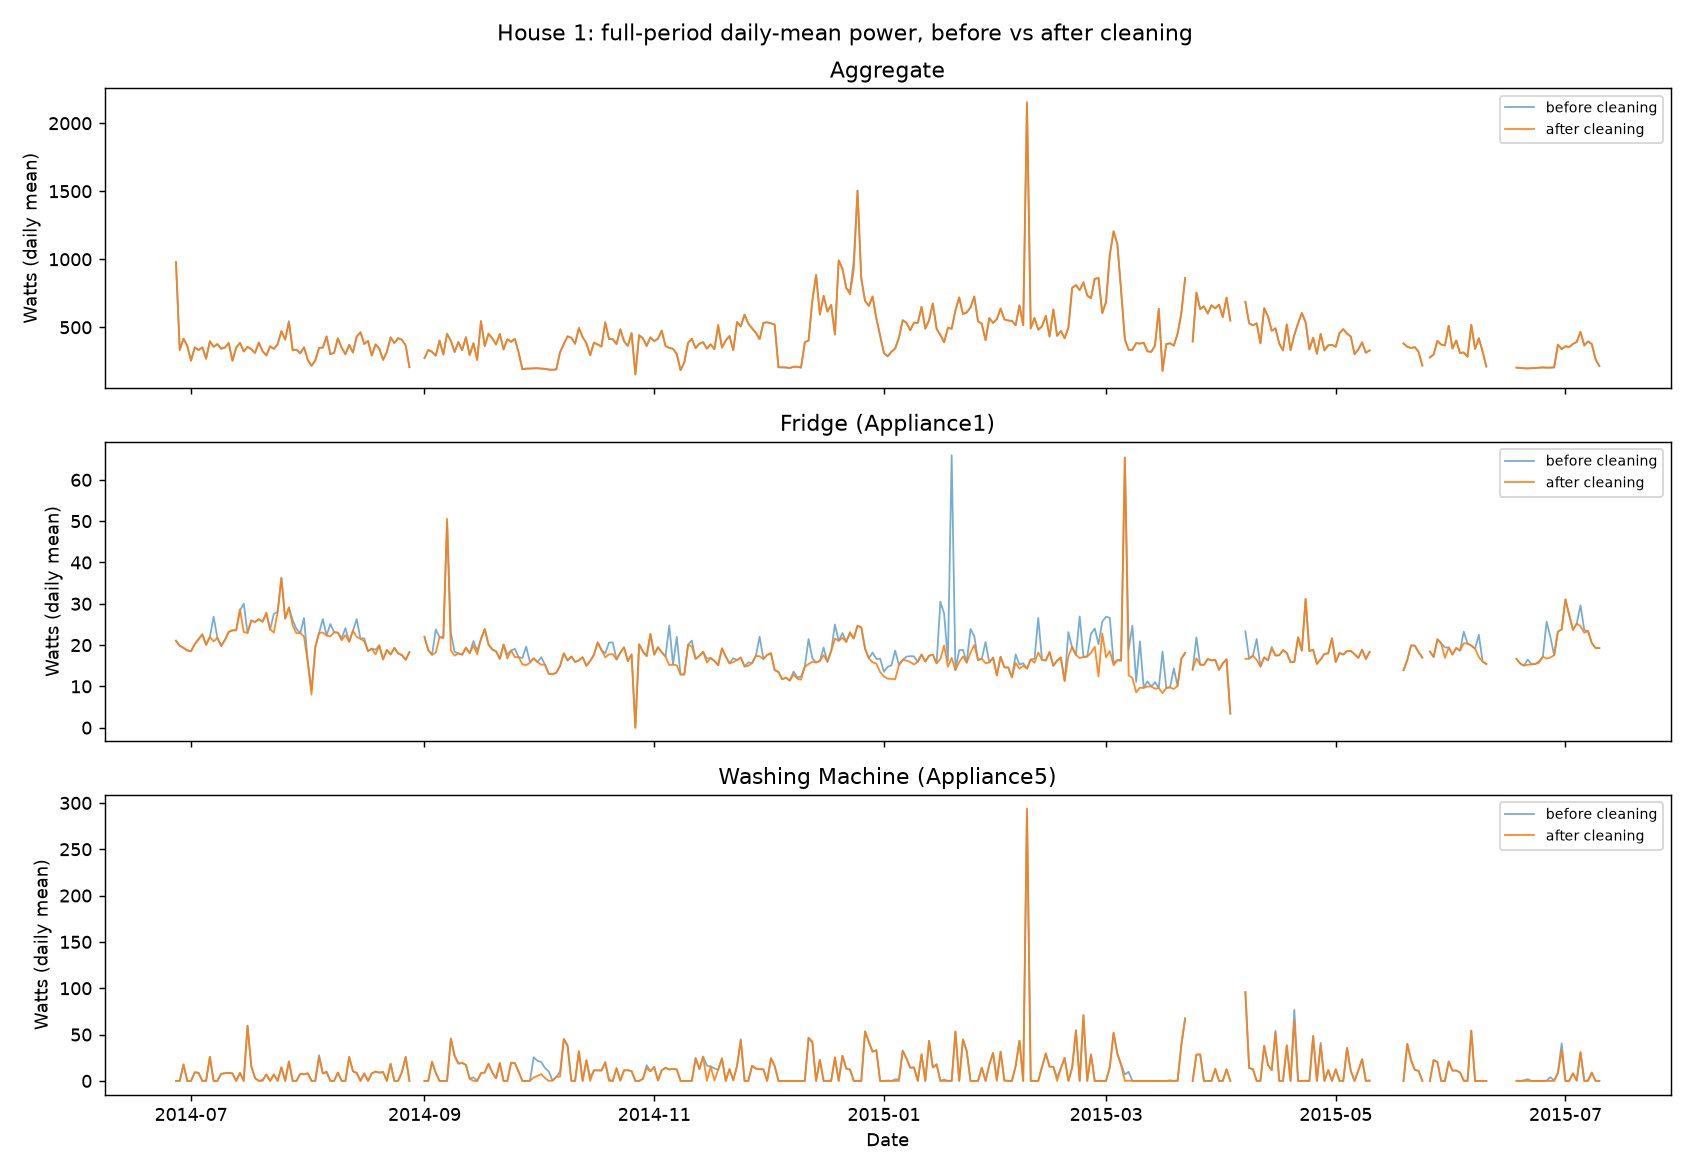

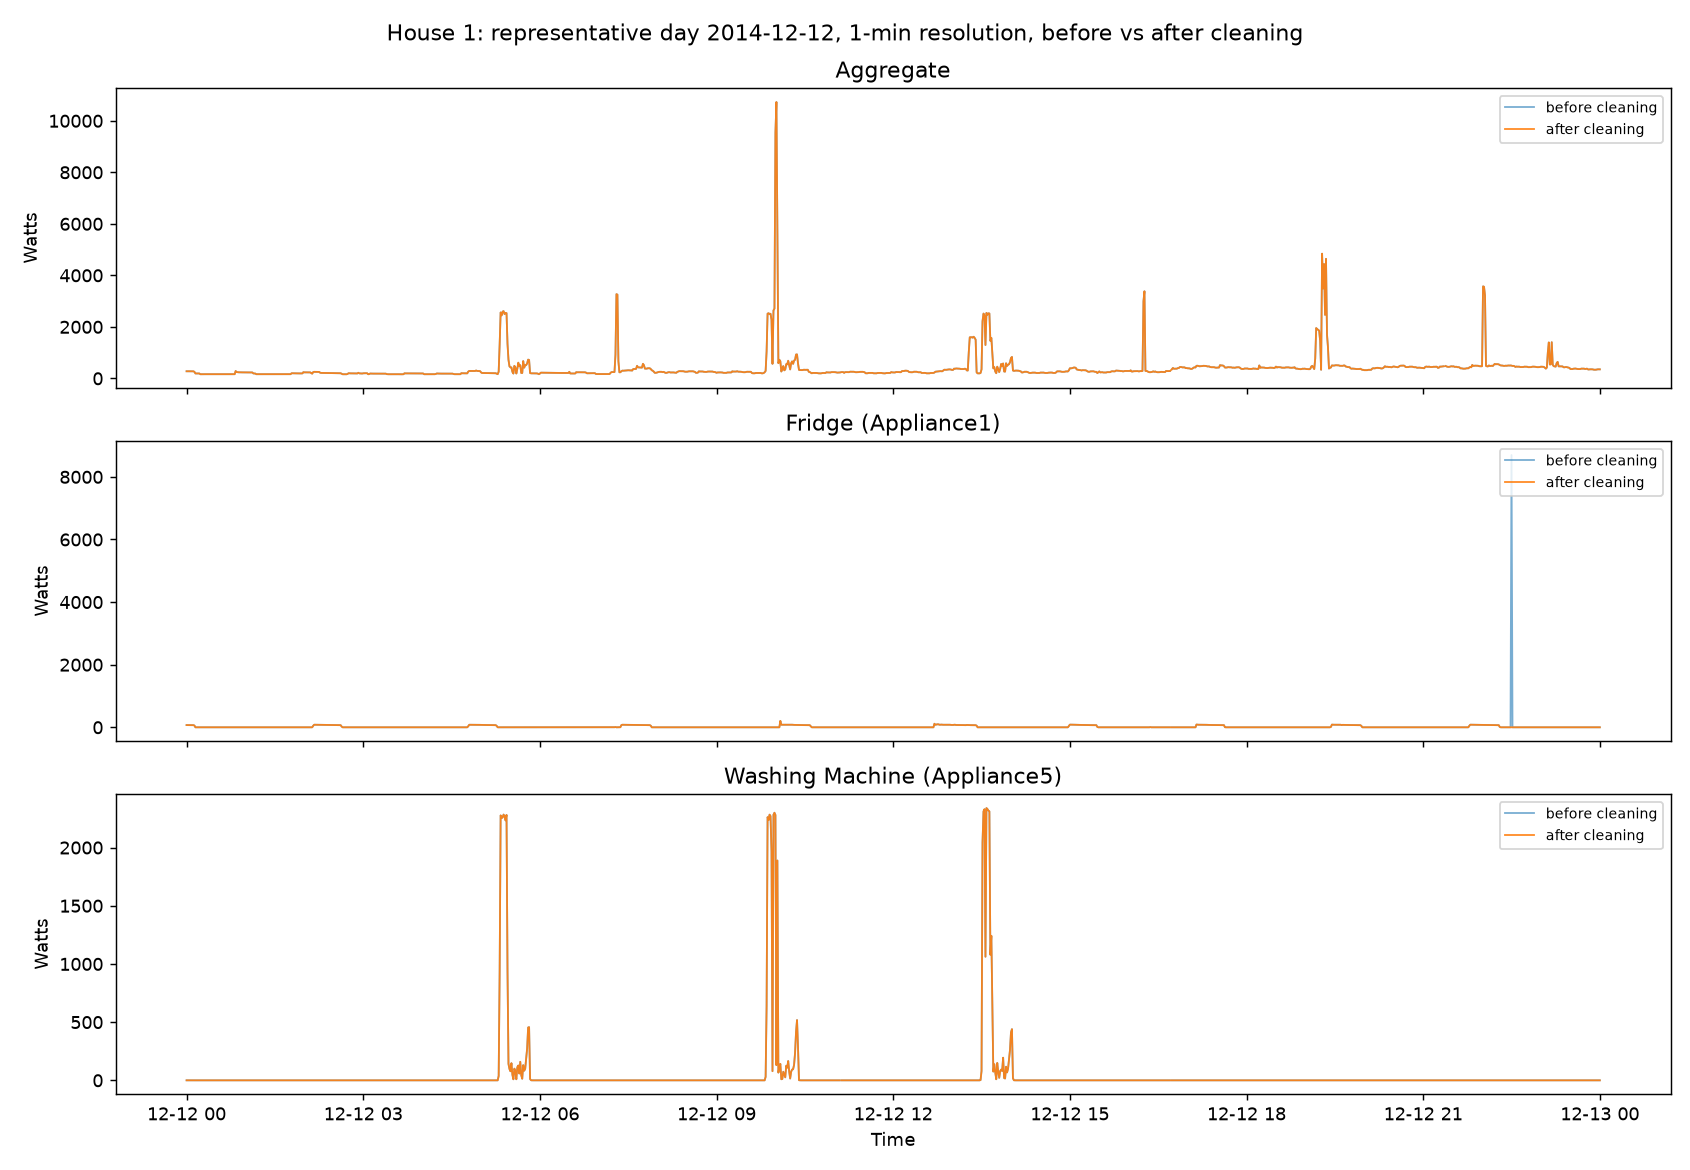

In [4]:
display(Image(filename=f'{FIG}/house1_overview_before_after.png'))
display(Image(filename=f'{FIG}/house1_day_before_after.png'))

## Part 2 — Washing-machine EDA across 8 households (official cleaned data)

Cycle-detection rule, availability table, and plot interpretations: `../RESULTS.md`.

In [5]:
import washing_machine_eda
washing_machine_eda.main()

house 1: 414 cycles, 920091 bins, missing 12.91%


house 2: 345 cycles, 889078 bins, missing 24.65%


house 5: 966 cycles, 933593 bins, missing 12.69%


house 6: 140 cycles, 831480 bins, missing 15.03%


house 7: 881 cycles, 882970 bins, missing 13.14%


house 10: 669 cycles, 845257 bins, missing 11.00%


house 19: 271 cycles, 677470 bins, missing 6.53%


house 20: 198 cycles, 662864 bins, missing 6.01%



=== Availability ===
 house  wm_channel               start                 end  total_days  total_1min_bins  missing_pct  off_pct  n_cycles_detected  cycles_per_week
     1           5 2013-10-09 13:06:00 2015-07-10 11:56:00       639.0           920091        12.91    98.31                414             4.54
     2           2 2013-09-17 22:08:00 2015-05-28 08:05:00       617.4           889078        24.65    96.25                345             3.91
     5           3 2013-09-26 09:56:00 2015-07-06 17:48:00       648.3           933593        12.69    93.46                966            10.43
     6           2 2013-11-28 12:15:00 2015-06-28 22:14:00       577.4           831480        15.03    98.40                140             1.70
     7           5 2013-11-01 22:01:00 2015-07-08 02:10:00       613.2           882970        13.14    92.77                881            10.06
    10           5 2013-11-20 11:31:00 2015-06-30 11:07:00       587.0           845257        11.00  


Saved availability/cycles tables and 5 figures to figures/.


,house,wm_channel,start,end,total_days,total_1min_bins,missing_pct,off_pct,n_cycles_detected,cycles_per_week
0,1,5,2013-10-09 13:06:00,2015-07-10 11:56:00,639.0,920091,12.91,98.31,414,4.54
1,2,2,2013-09-17 22:08:00,2015-05-28 08:05:00,617.4,889078,24.65,96.25,345,3.91
2,5,3,2013-09-26 09:56:00,2015-07-06 17:48:00,648.3,933593,12.69,93.46,966,10.43
3,6,2,2013-11-28 12:15:00,2015-06-28 22:14:00,577.4,831480,15.03,98.40,140,1.70
4,7,5,2013-11-01 22:01:00,2015-07-08 02:10:00,613.2,882970,13.14,92.77,881,10.06
5,10,5,2013-11-20 11:31:00,2015-06-30 11:07:00,587.0,845257,11.00,92.08,669,7.98
6,19,2,2014-03-06 16:23:00,2015-06-20 03:32:00,470.5,677470,6.53,96.36,271,4.03
7,20,4,2014-03-20 12:01:00,2015-06-23 19:44:00,460.3,662864,6.01,97.62,198,3.01


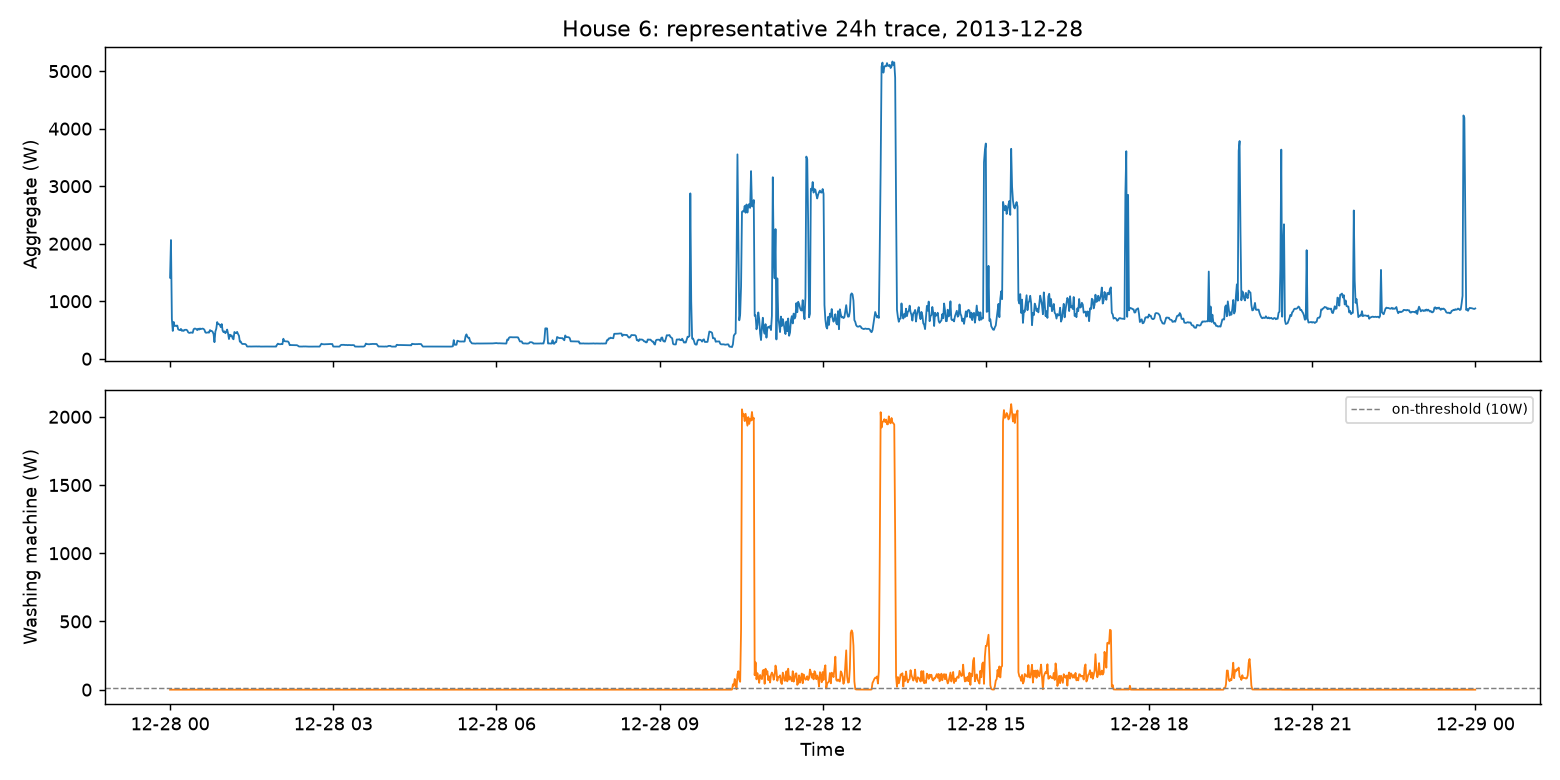

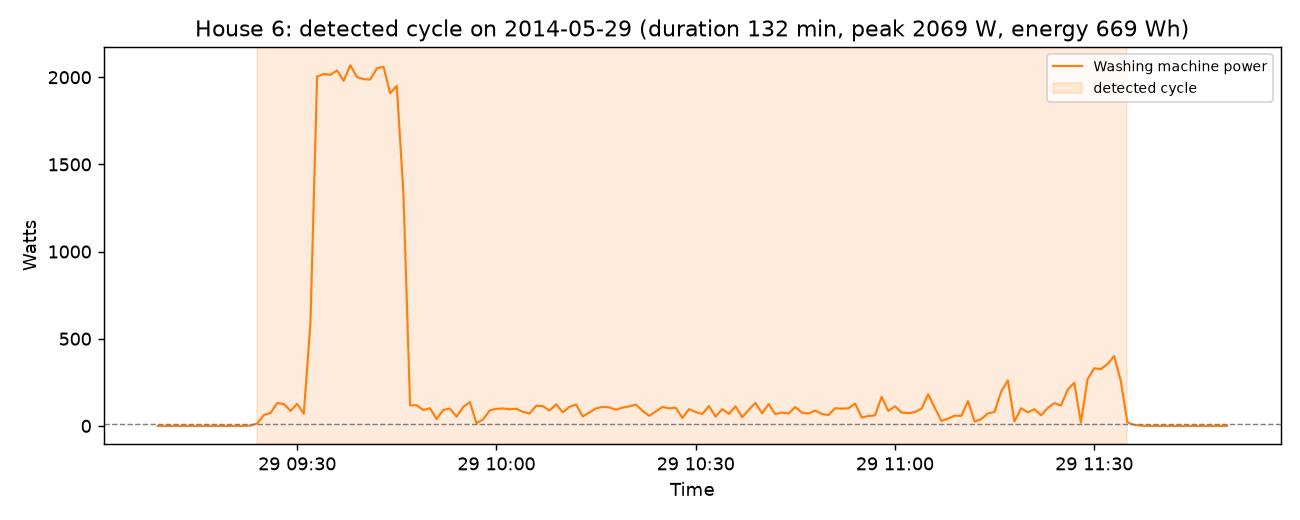

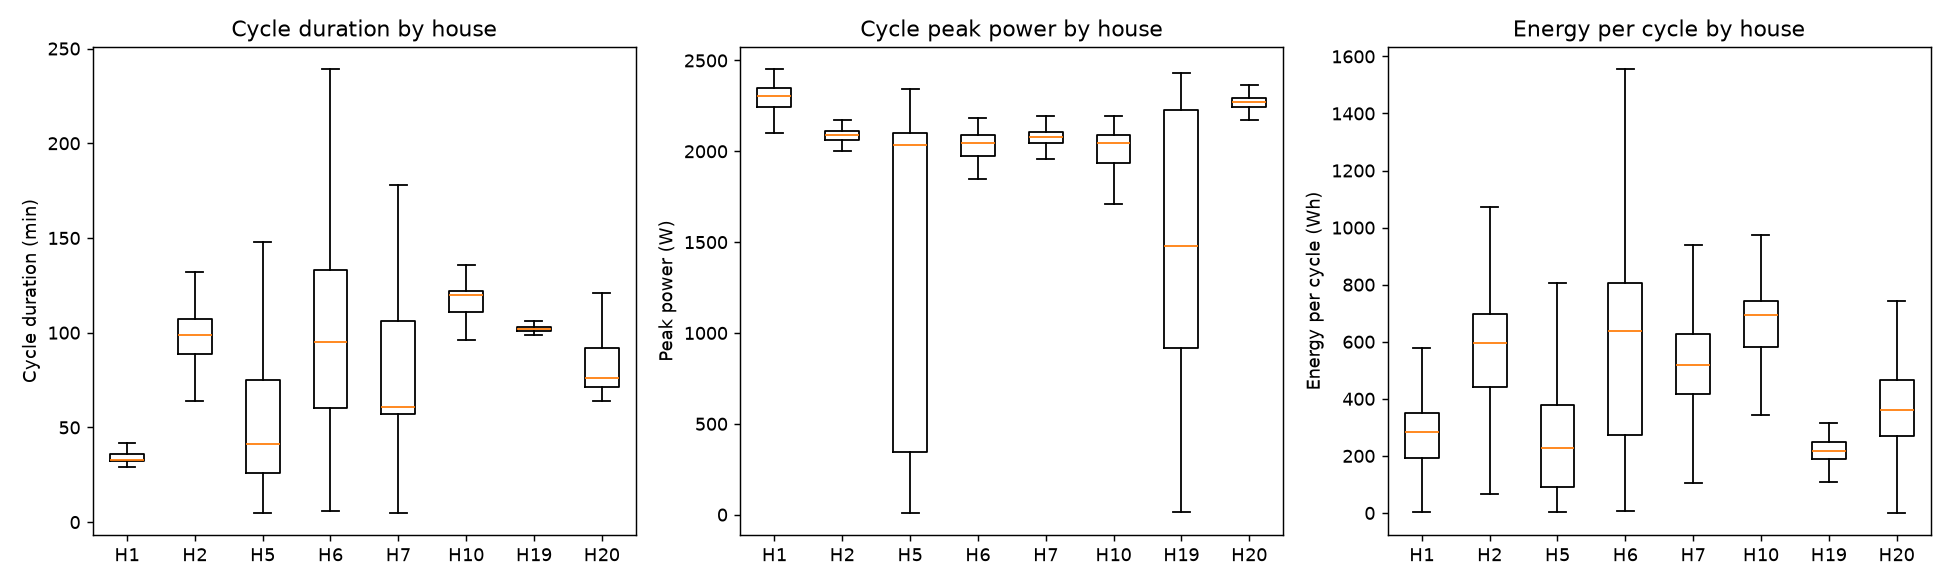

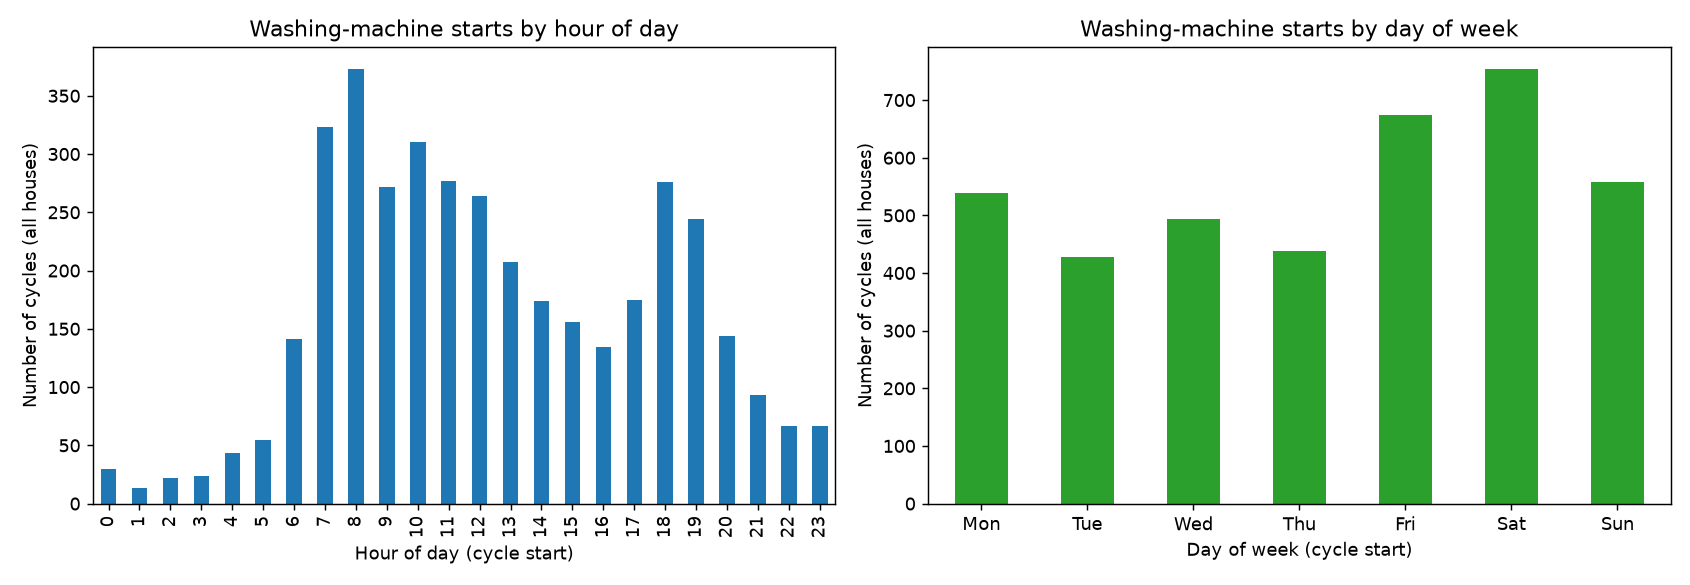

In [6]:
display(pd.read_csv(f'{PROC}/wm_availability.csv'))
for f in ['wm_24h_trace_house6.png', 'wm_detected_cycle_house6.png', 'wm_cross_house_comparison.png', 'wm_usage_patterns.png']:
    display(Image(filename=f'{FIG}/{f}'))

## Part 3 — Disaggregation model: baselines, LightGBM, household-split vs time-split

Full discussion, metrics interpretation and failure analysis: `../RESULTS.md`. This cell takes ~25s (trains 2 LightGBM models on ~3-4M rows each).

In [7]:
import disaggregation_model
disaggregation_model.main()

Loading + building features for train/val/test houses...


train rows=2992921, val rows=766970, test rows=2008529
n features=29


                     label  MAE_W  RMSE_W    SAE  on_off_F1  on_off_precision  on_off_recall  n_rows
       baseline_always_off  16.10  148.44 1.0000     0.0000            0.0000         0.0000 2008529
   baseline_hourly_profile  28.74  147.53 0.1015     0.1191            0.0654         0.6627 2008529
            lightgbm_model  16.12  148.40 0.9977     0.0011            0.1585         0.0005 2008529
lightgbm_model_active_only 300.55  641.88 0.9992     0.0011            1.0000         0.0005  107365
          lightgbm_house10  31.90  213.99 0.9980     0.0002            0.0295         0.0001  752265
          lightgbm_house19   5.66   57.75 0.9984     0.0001            0.0833         0.0000  633226
          lightgbm_house20   7.68  110.99 0.9955     0.0062            0.5904         0.0031  623038

Top 10 features by gain:
         feature   importance
 agg_roll_min_60 54371.330338
agg_roll_mean_60 23820.973419
 agg_roll_min_30 19540.732330
 agg_roll_max_60 18146.177933
        hour_sin


Saved model_results.csv, feature_importance.csv, model_summary.json, and plot.

=== Experiment B: time-based split within known households ===


train rows=4037890, val rows=865264, test rows=865266


[50]	valid_0's l1: 21.1344


[100]	valid_0's l1: 21.0757


[150]	valid_0's l1: 21.0443


[200]	valid_0's l1: 21.0301


                            label  MAE_W  RMSE_W    SAE  on_off_F1  on_off_precision  on_off_recall  n_rows
    timesplit_baseline_always_off  20.03  170.44 1.0000     0.0000            0.0000         0.0000  865266
timesplit_baseline_hourly_profile  34.25  168.86 0.1623     0.1322            0.0721         0.7905  865266
         timesplit_lightgbm_model  19.63  166.53 0.9315     0.4441            0.6613         0.3343  865266
   timesplit_lightgbm_active_only 335.54  697.36 0.9549     0.5011            1.0000         0.3343   49312
best_iteration=176


Experiment A: household split (fully held-out test houses)


,label,MAE_W,RMSE_W,SAE,on_off_F1,on_off_precision,on_off_recall,n_rows
0,baseline_always_off,16.10,148.44,1.0000,0.0000,0.0000,0.0000,2008529
1,baseline_hourly_profile,28.74,147.53,0.1015,0.1191,0.0654,0.6627,2008529
2,lightgbm_model,16.12,148.40,0.9977,0.0011,0.1585,0.0005,2008529
3,lightgbm_model_active_only,300.55,641.88,0.9992,0.0011,1.0000,0.0005,107365
4,lightgbm_house10,31.90,213.99,0.9980,0.0002,0.0295,0.0001,752265
5,lightgbm_house19,5.66,57.75,0.9984,0.0001,0.0833,0.0000,633226
6,lightgbm_house20,7.68,110.99,0.9955,0.0062,0.5904,0.0031,623038


Experiment B: time split (seen households, later time period)


,label,MAE_W,RMSE_W,SAE,on_off_F1,on_off_precision,on_off_recall,n_rows
0,timesplit_baseline_always_off,20.03,170.44,1.0000,0.0000,0.0000,0.0000,865266
1,timesplit_baseline_hourly_profile,34.25,168.86,0.1623,0.1322,0.0721,0.7905,865266
2,timesplit_lightgbm_model,19.63,166.53,0.9315,0.4441,0.6613,0.3343,865266
3,timesplit_lightgbm_active_only,335.54,697.36,0.9549,0.5011,1.0000,0.3343,49312


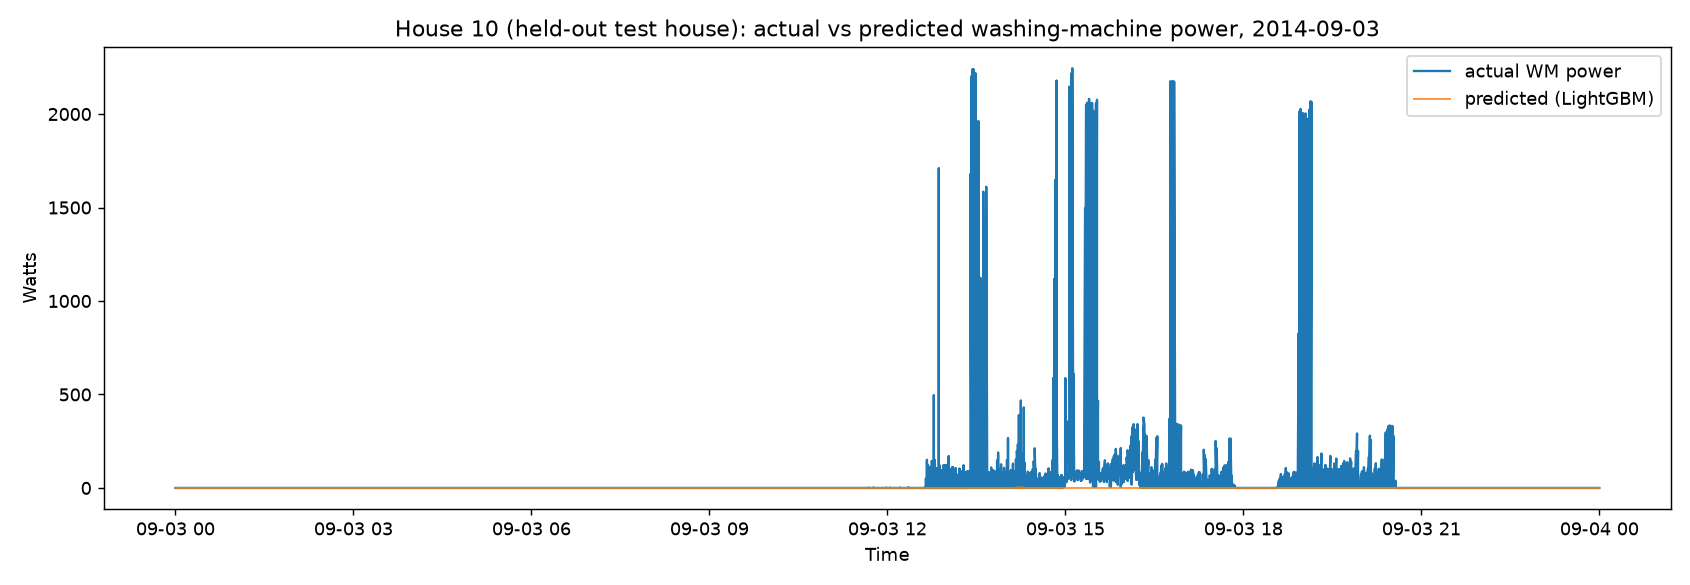

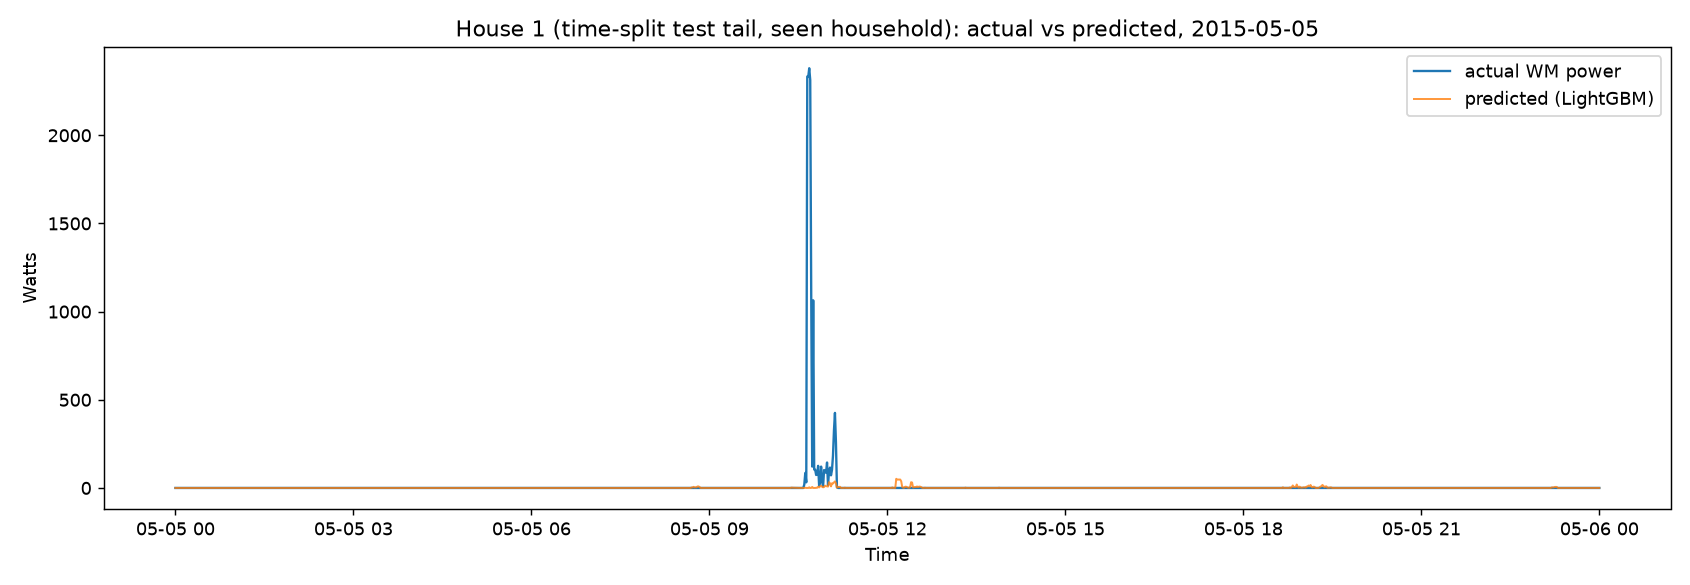

In [8]:
print('Experiment A: household split (fully held-out test houses)')
display(pd.read_csv(f'{PROC}/model_results.csv'))
print('Experiment B: time split (seen households, later time period)')
display(pd.read_csv(f'{PROC}/model_results_timesplit.csv'))
display(Image(filename=f'{FIG}/model_actual_vs_predicted_house10.png'))
display(Image(filename=f'{FIG}/model_actual_vs_predicted_timesplit_house1.png'))